# 01 - Exploratory data analysis

Binary sentiment classification (positive vs negative) on Reddit comments from **GoEmotions**.
This notebook checks the quality of the raw data, verifies the official sentiment mapping, describes
the balanced 500/500 dataset and justifies the preprocessing choices used by the models
(cleaning, stopword policy, sequence length and train-only vocabulary).

All the reusable logic lives in `src/preprocessing.py` and `src/visualize.py`; this notebook only
calls it and looks at the results. Figures are saved to `outputs/figures/` with the prefix `eda_`.

In [1]:
import sys
from collections import Counter
from pathlib import Path

sys.path.append("..")

import emoji
import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd

from src import preprocessing as pp
from src import visualize as viz

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)

DATA_DIR = Path("../data")
print("SEED =", pp.SEED, "| MAX_LEN =", pp.MAX_LEN, "| LABELS =", pp.LABELS)

SEED = 42 | MAX_LEN = 30 | LABELS = {'negative': 0, 'positive': 1}


## 1. Raw GoEmotions and data quality

The filtered version of GoEmotions has three TSV files (train, dev, test) with the comment text,
the comma-separated emotion ids and the Reddit comment id. They are joined into one table because
the balanced dataset is built from the whole corpus. If the raw files are missing,
`download_raw()` gets them from the authors' repository.

In [2]:
if not (pp.RAW_DIR / "train.tsv").exists():
    pp.download_raw()

df = pp.load_goemotions()
print(f"Comments: {len(df):,}")
display(df["split"].value_counts().rename("comments").to_frame())
df.head()

Comments: 54,263


,comments
split,
train,43410
test,5427
dev,5426


,text,emotion_ids,comment_id,split
0,My favourite food is anything I didn't have to cook myself.,[27],eebbqej,train
1,"Now if he does off himself, everyone will think hes having a laugh screwing with people instead of actually dead",[27],ed00q6i,train
2,WHY THE FUCK IS BAYLESS ISOING,[2],eezlygj,train
3,To make her feel threatened,[14],ed7ypvh,train
4,Dirty Southern Wankers,[3],ed0bdzj,train


### 1.1 Missing values, empty texts and repeated ids

The files are read as strings with `keep_default_na=False`, so a comment such as "NA" or "null"
stays a text. Here we check for real missing values, texts that are empty after stripping spaces
and repeated comment ids.

In [3]:
quality = pd.Series({
    "rows": len(df),
    "missing values (any column)": int(df.isna().sum().sum()),
    "empty texts (after strip)": int((df["text"].str.strip() == "").sum()),
    "comments without emotion ids": int((df["emotion_ids"].str.len() == 0).sum()),
    "repeated comment_id": int(df["comment_id"].duplicated().sum()),
    "texts that look like NA/null/none": int(df["text"].str.strip().str.lower().isin(["na", "nan", "null", "none"]).sum()),
}, name="count")
quality.to_frame()

,count
rows,54263
missing values (any column),0
empty texts (after strip),0
comments without emotion ids,0
repeated comment_id,0
texts that look like NA/null/none,0


### 1.2 Duplicated comments in the full corpus

Two comments are considered the same when their texts match after `strip()` and lowercase
(the same normalization used later by `deduplicate_texts`). Duplicates are mostly short,
generic replies that many users write.

In [4]:
norm = df["text"].str.strip().str.lower()
is_repeated = norm.duplicated(keep=False)
dup_summary = pd.Series({
    "rows that are a repeated copy": int(norm.duplicated().sum()),
    "distinct texts that appear more than once": int(norm[is_repeated].nunique()),
    "rows involved in a repetition": int(is_repeated.sum()),
}, name="count")
display(dup_summary.to_frame())

most_repeated = norm[is_repeated].value_counts().head(10).rename("copies").to_frame()
most_repeated

,count
rows that are a repeated copy,320
distinct texts that appear more than once,186
rows involved in a repetition,506


,copies
text,
thank you!,16
thank you.,15
happy cake day!,12
happy cake day,7
weird flex but ok,7
i love [name],6
[name],6
i like it,6
[name].,6


### 1.3 Comment length and masked tokens

GoEmotions already replaces person names with `[NAME]` and religions with `[RELIGION]`.
These placeholders are kept as tokens (`nametoken`, `religiontoken`) instead of being deleted,
because they carry part of the structure of the sentence ("[NAME] you are the best").

In [5]:
df["n_words"] = df["text"].str.split().str.len()
length_stats = df["n_words"].describe(percentiles=[0.5, 0.95, 0.99]).round(2)
display(length_stats.to_frame("words per comment").T)

masked = pd.DataFrame({
    "comments": [df["text"].str.contains(r"\[NAME\]").sum(), df["text"].str.contains(r"\[RELIGION\]").sum()],
}, index=["[NAME]", "[RELIGION]"])
masked["share"] = (masked["comments"] / len(df)).map("{:.2%}".format)
display(masked)

other = pd.Series({
    "comments with a URL": int(df["text"].str.contains(r"https?://|www\.").sum()),
    "comments with at least one emoji": int(df["text"].apply(lambda s: emoji.emoji_count(s) > 0).sum()),
    "comments with 1 or 2 words": int((df["n_words"] <= 2).sum()),
}, name="count")
other.to_frame()

,count,mean,std,min,50%,95%,99%,max
words per comment,54263.0,12.83,6.71,1.0,12.0,24.0,27.0,33.0


,comments,share
[NAME],7558,13.93%
[RELIGION],121,0.22%


,count
comments with a URL,0
comments with at least one emoji,1062
comments with 1 or 2 words,1295


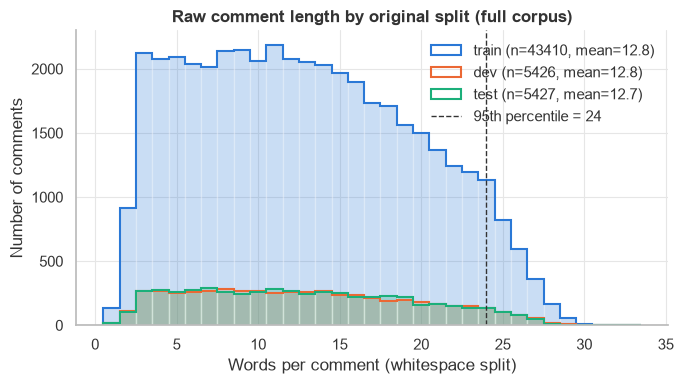

In [6]:
fig = viz.plot_length_hist(
    {split: df.loc[df["split"] == split, "n_words"] for split in pp.SPLITS},
    title="Raw comment length by original split (full corpus)",
    xlabel="Words per comment (whitespace split)",
    name="eda_raw_length_by_split",
    percentile=95,
)

The three original splits have the same length distribution, so joining them does not mix
different kinds of comments. Comments are short (Reddit replies): the longest raw comment has
33 words, which is already a first hint that very long sequences are not needed.

## 2. Sentiment mapping

The official `sentiment_mapping.json` groups the 27 emotions into positive, negative and ambiguous.
Rule used by `assign_sentiment`: every emotion of a comment is mapped to its group, with
`neutral` as a group of its own. A comment gets a sentiment only if **all** its emotions belong to
the same group; any combination of groups (including neutral plus another emotion) is `mixed`.
Only positive and negative comments are used for the binary task.

In [7]:
mapping = pp.load_sentiment_mapping()
for group, emotions in mapping.items():
    print(f"{group:<9} ({len(emotions):>2}): {', '.join(emotions)}")

data = pp.add_sentiment(df)
group_counts = pp.check_sentiment_counts(data)  # asserts the expected counts
print("\nThe counts match the expected values for the 54,263 comments.")
group_counts = group_counts.reindex(["positive", "negative", "neutral", "ambiguous", "mixed"])
group_counts.to_frame("comments").assign(share=lambda t: (t["comments"] / t["comments"].sum()).map("{:.1%}".format))

positive  (12): amusement, excitement, joy, love, desire, optimism, caring, pride, admiration, gratitude, relief, approval
negative  (11): fear, nervousness, remorse, embarrassment, disappointment, sadness, grief, disgust, anger, annoyance, disapproval
ambiguous ( 4): realization, surprise, curiosity, confusion

The counts match the expected values for the 54,263 comments.


,comments,share
sentiment,,
positive,19020,35.1%
negative,10217,18.8%
neutral,16021,29.5%
ambiguous,4805,8.9%
mixed,4200,7.7%


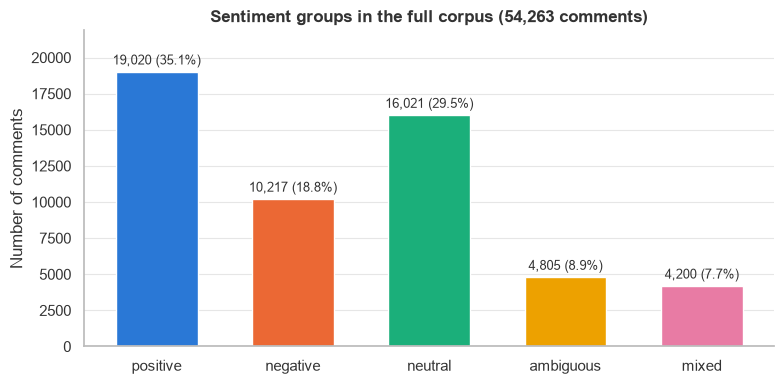

In [8]:
fig = viz.plot_class_balance(group_counts, title="Sentiment groups in the full corpus (54,263 comments)",
                             name="eda_sentiment_groups")

Positive comments are almost twice as frequent as negative ones (19,020 vs 10,217). Without
balancing, a model could reach about 65% accuracy by always predicting positive, which is why the
task asks for a balanced 500/500 sample.

### 2.1 Most frequent emotions in each class

An emotion is counted once for every comment where it appears.

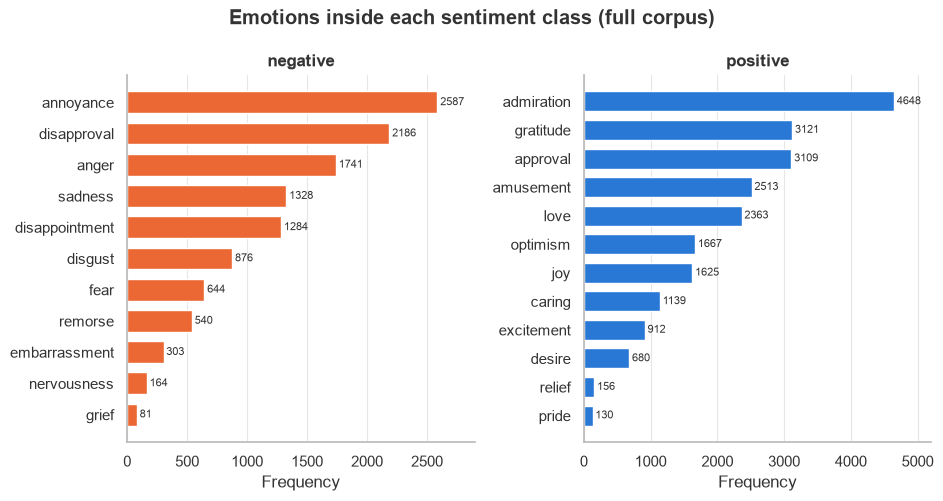

In [9]:
def emotion_counts(frame: pd.DataFrame) -> list[tuple[str, int]]:
    """Frequency of each emotion name over the comments of frame."""
    return Counter(e for emotions in frame["emotions"] for e in emotions).most_common()

top_emotions = {s: emotion_counts(data[data["sentiment"] == s]) for s in pp.LABELS}
fig = viz.plot_top_ngrams({"negative": top_emotions["negative"], "positive": top_emotions["positive"]},
                          n=12, title="Emotions inside each sentiment class (full corpus)",
                          name="eda_top_emotions")

The negative class is dominated by **annoyance, disapproval and anger**, and the positive class by
**admiration, gratitude and approval**. Several of these are mild or conversational
(approval, disapproval, annoyance), so many comments will not contain strong sentiment words.

### 2.2 Multi-label comments

GoEmotions is multi-label. The table shows how many emotions each comment has per sentiment group,
and why the `mixed` group exists.

In [10]:
data["n_emotions"] = data["emotion_ids"].str.len()
multi = pd.crosstab(data["sentiment"], data["n_emotions"], margins=True, margins_name="total")
display(multi)

mixed = data[data["sentiment"] == "mixed"]
with_neutral = mixed["emotions"].apply(lambda es: "neutral" in es)
print(f"mixed comments: {len(mixed):,}, of which {with_neutral.sum():,} combine neutral with another emotion")
for s in pp.LABELS:
    part = data[data["sentiment"] == s]
    print(f"{s}: {(part['n_emotions'] > 1).mean():.1%} of the comments have more than one emotion (all in the same group)")

n_emotions,1,2,3,4,5,total
sentiment,,,,,,
ambiguous,4437,360,8,0,0,4805
mixed,0,3810,367,23,0,4200
negative,8797,1328,88,3,1,10217
neutral,16021,0,0,0,0,16021
positive,16191,2626,192,11,0,19020
total,45446,8124,655,37,1,54263


mixed comments: 4,200, of which 1,751 combine neutral with another emotion
negative: 13.9% of the comments have more than one emotion (all in the same group)
positive: 14.9% of the comments have more than one emotion (all in the same group)


About 14-15% of the positive and negative comments have two or more emotions, but all of them in
the same group, so the binary label is not ambiguous. Comments that mix groups are discarded.

## 3. Balanced dataset

`build_balanced_dataset` keeps the positive and negative comments, removes duplicates and samples
500 comments per class with `SEED = 42` from train + dev + test together. Then `split_dataset` makes a
stratified 80/20 split. The result is stored in `data/processed/`; here we recompute the
deduplication numbers and check the saved files.

In [11]:
candidates = data[data["sentiment"].isin(pp.LABELS)]
dedup, dedup_stats = pp.deduplicate_texts(candidates)
display(pd.Series(dedup_stats, name="count").to_frame())

conflict_norm = candidates["text"].str.strip().str.lower()
n_sent = candidates.groupby(conflict_norm)["sentiment"].transform("nunique")
print("Text with conflicting labels:")
display(candidates.loc[n_sent > 1, ["text", "emotions", "sentiment"]])
display(pd.DataFrame({"before dedup": candidates["sentiment"].value_counts(),
                      "after dedup": dedup["sentiment"].value_counts()}))

,count
rows_before,29237
repeated_texts,124
exact_duplicates_removed,213
conflicting_texts,1
conflicting_rows_removed,3
rows_after,29021


Text with conflicting labels:


,text,emotions,sentiment
9494,Weird flex but ok,[disgust],negative
20915,Weird flex but ok,[annoyance],negative
24162,Weird flex but ok,[approval],positive


,before dedup,after dedup
sentiment,,
positive,19020,18833
negative,10217,10188


Removing duplicates **before** sampling avoids the same comment ending up in train and in test
(a form of leakage). Only one text had different labels in different copies ("positive" in one,
"negative" in another); all its copies are dropped because we cannot know which label is right.
After deduplication there are still far more than 500 comments per class, so sampling is easy.

In [12]:
read = lambda name: pd.read_csv(DATA_DIR / "processed" / f"{name}.csv", keep_default_na=False)
balanced, train, test = read("balanced"), read("train"), read("test")
pp.check_processed(balanced, train, test)  # sizes, 500/500, no repeated texts, no overlap
print("check_processed: OK")

sizes = pd.DataFrame({name: frame["sentiment"].value_counts() for name, frame in
                      [("balanced", balanced), ("train", train), ("test", test)]}).T
sizes["total"] = sizes.sum(axis=1)
sizes

check_processed: OK


sentiment,positive,negative,total
balanced,500,500,1000
train,400,400,800
test,100,100,200


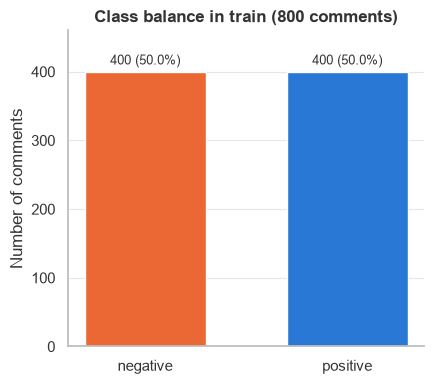

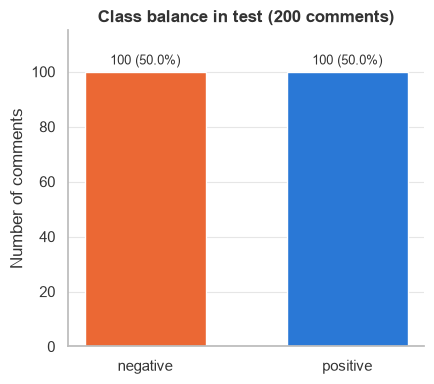

In [13]:
for name, frame in [("train", train), ("test", test)]:
    counts = frame["sentiment"].value_counts().reindex(["negative", "positive"])
    fig = viz.plot_class_balance(counts, title=f"Class balance in {name} ({len(frame)} comments)",
                                 name=f"eda_class_balance_{name}")

In [14]:
origin = balanced.merge(df[["comment_id", "split"]], on="comment_id", how="left")
pd.crosstab(origin["sentiment"], origin["split"], margins=True, margins_name="total")

split,dev,test,train,total
sentiment,,,,
negative,53,54,393,500
positive,44,45,411,500
total,97,99,804,1000


Train has 400/400 and test 100/100, so accuracy is a fair metric and the majority baseline is 50%.
The sample comes from the three original splits roughly in proportion to their sizes
(about 80% from the original train file), as expected from uniform sampling.

## 4. Sentence length

Length is measured in words (whitespace split) on the raw text and in tokens after cleaning
(`clean_text`, the input of the vectorizer). This decides the sequence length `MAX_LEN` used by
the Dense, RNN and LSTM models.

In [15]:
balanced["raw_words"] = balanced["text"].str.split().str.len()
balanced["clean_tokens"] = balanced["clean_text"].apply(lambda s: len(pp.tokenize(s)))

def length_table(col: str) -> pd.DataFrame:
    """Mean, percentiles and max of a length column per class."""
    rows = {}
    for s in pp.LABELS:
        v = balanced.loc[balanced["sentiment"] == s, col]
        rows[s] = {"mean": v.mean(), "median": v.median(), "p95": np.percentile(v, 95),
                   "p99": np.percentile(v, 99), "max": v.max()}
    v = balanced[col]
    rows["all"] = {"mean": v.mean(), "median": v.median(), "p95": np.percentile(v, 95),
                   "p99": np.percentile(v, 99), "max": v.max()}
    return pd.DataFrame(rows).T.round(2)

display(length_table("raw_words").rename_axis("raw words"))
display(length_table("clean_tokens").rename_axis("clean tokens"))

,mean,median,p95,p99,max
raw words,,,,,
negative,13.28,13.0,25.00,27.0,29.0
positive,12.83,13.0,24.00,27.0,28.0
all,13.06,13.0,24.05,27.0,29.0


,mean,median,p95,p99,max
clean tokens,,,,,
negative,7.14,7.0,13.0,15.01,18.0
positive,6.82,6.0,13.0,16.00,20.0
all,6.98,7.0,13.0,16.00,20.0


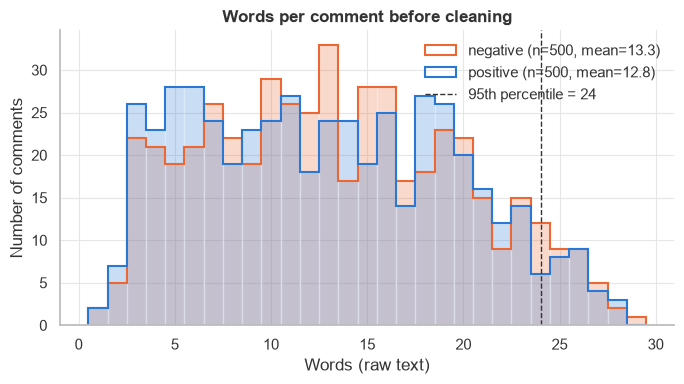

In [16]:
fig = viz.plot_length_hist(
    {s: balanced.loc[balanced["sentiment"] == s, "raw_words"] for s in ["negative", "positive"]},
    title="Words per comment before cleaning", xlabel="Words (raw text)",
    name="eda_length_raw", percentile=95)

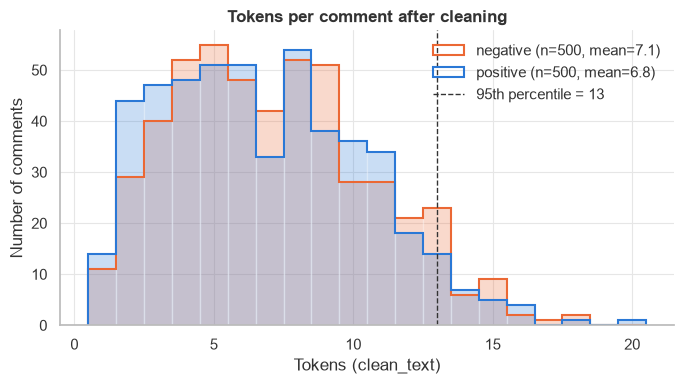

In [17]:
fig = viz.plot_length_hist(
    {s: balanced.loc[balanced["sentiment"] == s, "clean_tokens"] for s in ["negative", "positive"]},
    title="Tokens per comment after cleaning", xlabel="Tokens (clean_text)",
    name="eda_length_clean", percentile=95)

Both classes have almost the same length distribution, so length alone does not separate them.
Cleaning roughly halves the length (stopwords and punctuation go away).

To make sure the choice of `MAX_LEN` does not depend on the 1,000 sampled comments only, we also
clean the whole pool of deduplicated positive/negative candidates (about 29k comments).

In [18]:
pool_lengths = dedup["text"].apply(lambda s: len(pp.tokenize(pp.clean_text(s))))
pool_raw = dedup["text"].str.split().str.len()
pd.DataFrame({
    "raw words": [pool_raw.mean(), np.percentile(pool_raw, 95), np.percentile(pool_raw, 99), pool_raw.max(),
                  (pool_raw > pp.MAX_LEN).mean() * 100],
    "clean tokens": [pool_lengths.mean(), np.percentile(pool_lengths, 95), np.percentile(pool_lengths, 99),
                     pool_lengths.max(), (pool_lengths > pp.MAX_LEN).mean() * 100],
}, index=["mean", "p95", "p99", "max", f"% longer than MAX_LEN={pp.MAX_LEN}"]).round(2)

,raw words,clean tokens
mean,12.79,6.79
p95,24.00,13.00
p99,27.00,15.00
max,31.00,38.00
% longer than MAX_LEN=30,0.00,0.01


In [19]:
too_long = dedup.loc[pool_lengths > pp.MAX_LEN, ["sentiment", "text"]].assign(clean_tokens=pool_lengths[pool_lengths > pp.MAX_LEN])
print(f"Cleaned comments longer than {pp.MAX_LEN} tokens: {len(too_long)} of {len(dedup):,}")
too_long

Cleaned comments longer than 30 tokens: 2 of 29,021


,sentiment,text,clean_tokens
9194,positive,Wow that's so lit🔥🔥🔥😂😂💦💦💦 im so proud of your autistic son for making it LOL OUT LOUD 👏👏👏💦💦💦👏💦👏💦👏💦👏💦👏💦👏💦👏😘😘,38
16540,negative,🦀🦀🦀🦀🦀🦀🦀🦀🦀I’m bad at this game🦀🦀🦀🦀🦀🦀🦀🦀🦀🦀🦀🦀🦀🦀🦀🦀🦀🦀🦀🦀,31


**Choice of `MAX_LEN = 30`.** After cleaning, 95% of the balanced comments have at most 13 tokens,
99% at most 16, and the longest one has 20. In the whole positive/negative pool only 2 cleaned
comments are longer than 30 tokens, and they are runs of repeated emojis (each emoji becomes one
token); the raw texts are at most 31 words. With `MAX_LEN = 30` **no comment of the balanced dataset
is truncated** (checked again on the vectorized matrices in section 6), so the sequence models always
see the complete sentence. The cost is padding (76.8% of the positions of the train matrix are zeros), which the
recurrent models can skip with a masked embedding (`mask_zero=True`). A smaller value such as 16
(the p99) would save little computation on 800 training comments and would start to cut sentences.

## 5. Effect of the preprocessing

`clean_text` applies, in order: apostrophe normalization, `[NAME]` -> `nametoken` and
`[RELIGION]` -> `religiontoken`, URL removal, emojis -> word tokens (`emoji.demojize`), lowercase,
negation expansion (`don't` -> `do not`), removal of punctuation and digit-only tokens, and
removal of NLTK English stopwords **except negations**.

In [20]:
examples = balanced[
    balanced["text"].str.contains(r"\[NAME\]|n't|\bnot\b|\bno\b", regex=True)
    | balanced["text"].apply(lambda s: emoji.emoji_count(s) > 0)
].groupby("sentiment").head(4)
examples[["sentiment", "text", "clean_text"]]

,sentiment,text,clean_text
2,positive,"Normally don't like telling people the value of their opinion, but this opinion... Is 100% correct carry on",normally not like telling people value opinion opinion correct carry
3,positive,“That ad is an over-generalization!” “Most men feel this way and agree with me!” Hm. 🤔,ad generalization men feel way agree hm thinking_face
6,positive,[NAME] saw it during the football game and was super impressed!,nametoken saw football game super impressed
7,positive,good. can't even describe just how terrible this entire thing was. just make 1000% sure this is the right guy.,good not even describe terrible entire thing make sure right guy
16,negative,yup - he threw [NAME] under the bus with no guilt,yup threw nametoken bus no guilt
22,negative,Define abuse. People can down vote as they see fit but it doesn't mean it has to ruin your day.,define abuse people vote see fit not mean ruin day
26,negative,by the time I found it was a delay it was too late to go back to bed but I didn't have enough time to do anything fun,time found delay late go back bed not enough time anything fun
31,negative,Captain you ARE wrong. You’re wrong nooption to argue. I have the final rule ! Nope not gonna listen.,captain wrong wrong nooption argue final rule nope not gonna listen


In [21]:
stats = pp.cleaning_stats(balanced["text"], balanced["clean_text"])
display(pd.Series(stats, name="balanced dataset").to_frame())

full_stopwords = set(nltk.corpus.stopwords.words("english"))
kept = sorted(pp.NEGATIONS & full_stopwords)
print(f"NLTK English stopwords: {len(full_stopwords)}")
print(f"Removed by the pipeline: {len(pp.get_stopwords())}")
print(f"Kept because they are negations ({len(kept)}): {', '.join(kept)}")

,balanced dataset
empty_clean_texts,0.00
mean_tokens_before,13.05
mean_tokens_after,6.98


NLTK English stopwords: 198
Removed by the pipeline: 177
Kept because they are negations (21): aren't, couldn't, didn't, doesn't, don't, hadn't, hasn't, haven't, isn't, mightn't, mustn't, needn't, no, nor, not, shan't, shouldn't, wasn't, weren't, won't, wouldn't


### 5.1 Why negations are kept

The NLTK list contains `not`, `no`, `nor` and all the `n't` forms. Removing them changes the
meaning: "this is not good" would become "good". After `expand_negations` every negation becomes
the same token `not` (plus `no`, `never`, ... when they appear). Below we compare the share of
comments that contain at least one negation token with our policy and with the full NLTK list.

In [22]:
def without_any_stopwords(text: str) -> list[str]:
    """Tokens if the full NLTK list were removed (negations included)."""
    return [t for t in pp.tokenize(pp.clean_text(text, remove_stopwords=False)) if t not in full_stopwords]

balanced["tokens_full_removal"] = balanced["text"].apply(without_any_stopwords)
has_neg = lambda tokens: any(t in pp.NEGATIONS for t in tokens)
neg_table = pd.DataFrame({
    "comments with 'not' (kept negations)": balanced.groupby("sentiment")["clean_text"].apply(
        lambda c: c.apply(lambda s: "not" in pp.tokenize(s)).mean()),
    "comments with any negation (kept negations)": balanced.groupby("sentiment")["clean_text"].apply(
        lambda c: c.apply(lambda s: has_neg(pp.tokenize(s))).mean()),
    "comments with any negation (full NLTK list)": balanced.groupby("sentiment")["tokens_full_removal"].apply(
        lambda c: c.apply(has_neg).mean()),
})
display((neg_table * 100).round(1))

not_counts = {s: Counter(t for text in balanced.loc[balanced["sentiment"] == s, "clean_text"]
                         for t in pp.tokenize(text))["not"] for s in pp.LABELS}
print("Occurrences of the token 'not':", not_counts)
n_empty_full = int((balanced["tokens_full_removal"].str.len() == 0).sum())
print(f"Comments that would become empty with the full NLTK list: {n_empty_full}")

,comments with 'not' (kept negations),comments with any negation (kept negations),comments with any negation (full NLTK list)
sentiment,,,
negative,32.6,41.6,3.8
positive,16.8,20.8,1.8


Occurrences of the token 'not': {'negative': 179, 'positive': 88}
Comments that would become empty with the full NLTK list: 0


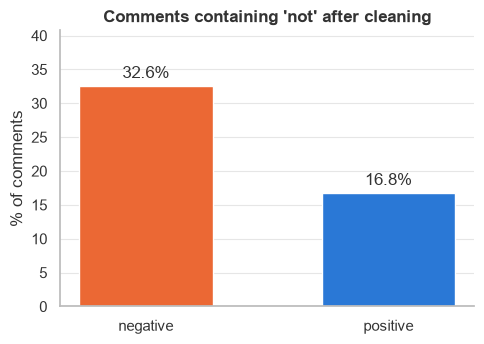

In [23]:
share_not = neg_table["comments with 'not' (kept negations)"].reindex(["negative", "positive"]) * 100
fig, ax = plt.subplots(figsize=(5, 3.6))
bars = ax.bar(share_not.index, share_not.values,
              color=[viz.CLASS_COLORS[s] for s in share_not.index], width=0.55)
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in share_not.values], padding=3)
ax.set_ylabel("% of comments")
ax.set_ylim(0, share_not.max() * 1.25)
ax.set_title("Comments containing 'not' after cleaning")
ax.grid(axis="x", visible=False)
fig.tight_layout()
viz.save_fig(fig, "eda_negation_share")
plt.show()

Negative comments contain `not` about **twice as often** as positive ones (32.6% vs 16.8% of the
comments). With the full NLTK list `not` would disappear completely and only 3.8% / 1.8% of the
comments would keep any negation word (`never`, `nothing`, ...). This is the main justification for
removing stopwords *except* negations: the classes stay distinguishable and phrases such as
"not happy" keep their meaning.

### 5.2 Emojis

Emojis are rare in this dataset but they are strong sentiment signals, so they are turned into words
instead of being dropped with the punctuation.

In [24]:
with_emoji = balanced[balanced["text"].apply(lambda s: emoji.emoji_count(s) > 0)]
emoji_tokens = Counter(emoji.demojize(e["emoji"]).strip(":").lower()
                       for text in with_emoji["text"] for e in emoji.emoji_list(text))
print(f"Balanced comments with emojis: {len(with_emoji)} "
      f"({with_emoji['sentiment'].value_counts().to_dict()})")
print("Most frequent:", emoji_tokens.most_common(8))
with_emoji[["sentiment", "text", "clean_text"]].head(6)

Balanced comments with emojis: 25 ({'positive': 20, 'negative': 5})
Most frequent: [('hundred_points', 5), ('smiling_face_with_heart-eyes', 4), ('rolling_on_the_floor_laughing', 4), ('smiling_face_with_sunglasses', 3), ('clapping_hands', 3), ('fire', 2), ('party_popper', 2), ('face_with_tears_of_joy', 2)]


,sentiment,text,clean_text
3,positive,“That ad is an over-generalization!” “Most men feel this way and agree with me!” Hm. 🤔,ad generalization men feel way agree hm thinking_face
28,positive,"Thanks for pointing them out, it's hard to see through my tears 😢",thanks pointing hard see tears crying_face
44,negative,"FUCK YOU CHAD, WE ARE COOL GAMERS RISE UP😎😎😎💯💯💯💯💯🔥🔥👅 BOTTOM TEXT",fuck chad cool gamers rise smiling_face_with_sunglasses smiling_face_with_sunglasses smiling_face_with_sunglasses hu...
51,positive,My exam is over and my winter break starts now 🎉🎉💃 I've been waiting for this omg,exam winter break starts party_popper party_popper woman_dancing waiting omg
73,positive,I like your baby😍,like baby smiling_face_with_heart_eyes
76,positive,Got me spitted coffee all over my phone🤣,got spitted coffee phone rolling_on_the_floor_laughing


## 6. Vocabulary

The vocabulary is computed **only on the training split** (800 comments), the same way the
vectorizer will be fitted. Test comments are never used to build features.

In [25]:
train_tokens = [t for text in train["clean_text"] for t in pp.tokenize(text)]
train_counts = Counter(train_tokens)
hapax = [w for w, c in train_counts.items() if c == 1]
vocab_summary = pd.Series({
    "tokens in train": len(train_tokens),
    "distinct words (vocabulary)": len(train_counts),
    "hapax (words seen once)": len(hapax),
    "hapax share of the vocabulary (%)": round(100 * len(hapax) / len(train_counts), 1),
    "words seen at least 3 times": sum(c >= 3 for c in train_counts.values()),
}, name="train")
vocab_summary.to_frame()

,train
tokens in train,5574.0
distinct words (vocabulary),2364.0
hapax (words seen once),1597.0
hapax share of the vocabulary (%),67.6
words seen at least 3 times,411.0


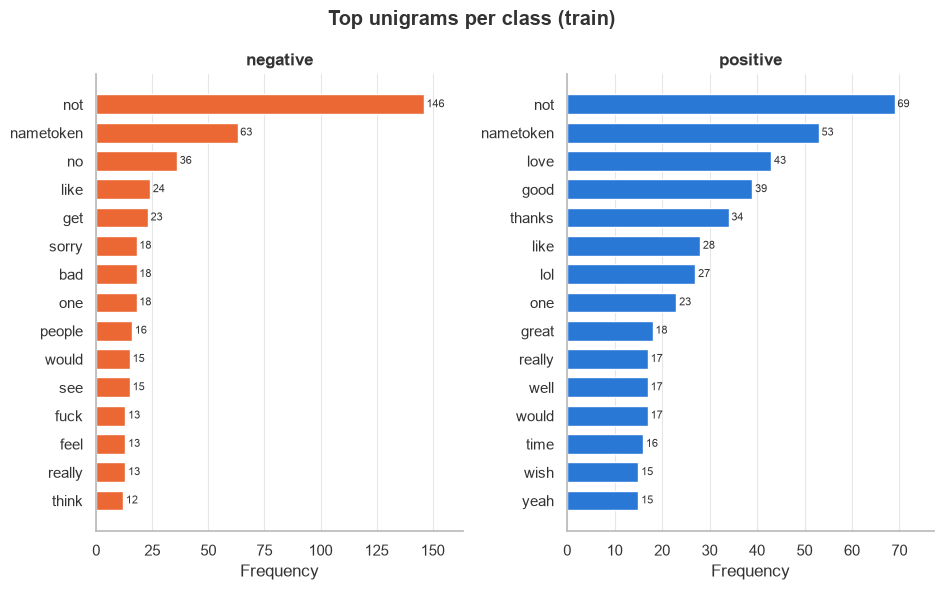

In [26]:
train_by_class = {s: train.loc[train["sentiment"] == s, "clean_text"] for s in ["negative", "positive"]}
unigrams = {s: viz.top_ngrams(texts, n=1, k=15) for s, texts in train_by_class.items()}
fig = viz.plot_top_ngrams(unigrams, n=15, title="Top unigrams per class (train)", name="eda_top_unigrams")

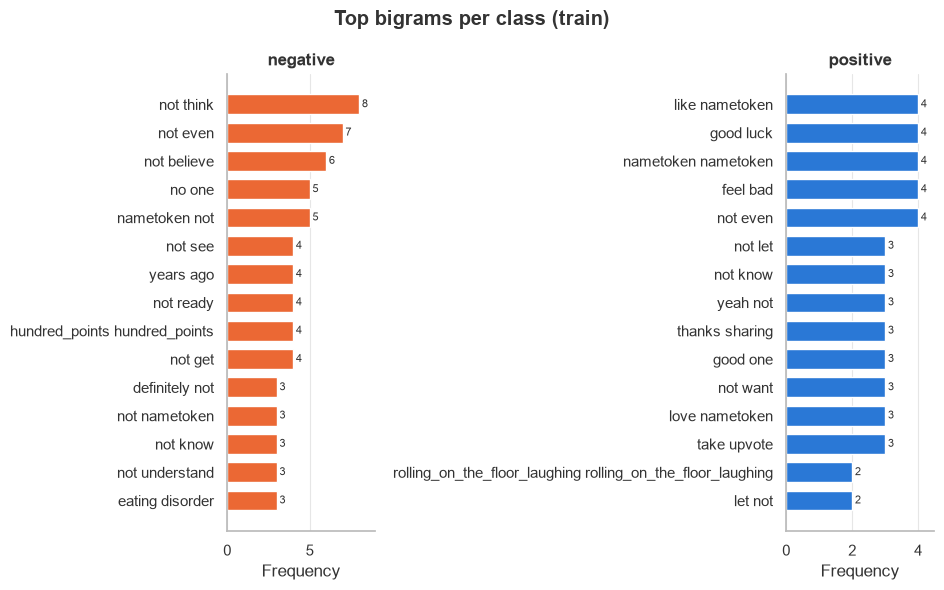

In [27]:
bigrams = {s: viz.top_ngrams(texts, n=2, k=15) for s, texts in train_by_class.items()}
fig = viz.plot_top_ngrams(bigrams, n=15, title="Top bigrams per class (train)", name="eda_top_bigrams")

`not` is the most frequent token in **both** classes, but twice as frequent in negative comments
(146 vs 69 occurrences in train). After it, positive comments use *love, good, thanks, lol, great*,
and negative ones *no, sorry, bad, fuck, people*. Most of the top negative bigrams are negation pairs
(*not think, not even, not believe, no one*), which again supports keeping negations. Several frequent
tokens appear in both classes (`nametoken`, *like, one, really, would*), and some negation pairs
also appear in positive comments (*not even, not know*), so single words are not enough and word
order and context should help: this is what the RNN and LSTM can exploit and the Dense model cannot.

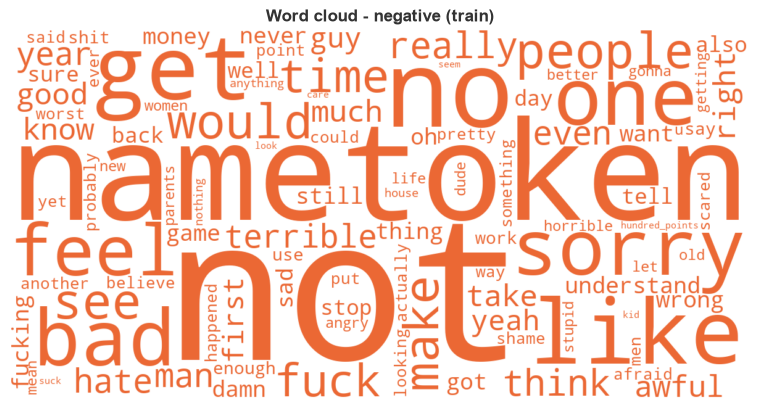

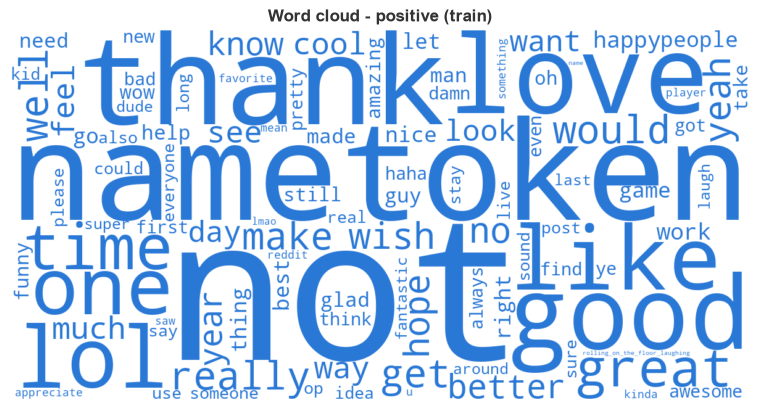

In [28]:
for s, texts in train_by_class.items():
    fig = viz.plot_wordcloud(" ".join(texts), title=f"Word cloud - {s} (train)",
                             color=viz.CLASS_COLORS[s], name=f"eda_wordcloud_{s}")

### 6.1 Words that separate the classes

A simple smoothed log-ratio of the relative frequency of each word in positive vs negative train
comments (words with at least 5 occurrences).

In [29]:
pos_c = Counter(t for text in train_by_class["positive"] for t in pp.tokenize(text))
neg_c = Counter(t for text in train_by_class["negative"] for t in pp.tokenize(text))
pos_total, neg_total = sum(pos_c.values()), sum(neg_c.values())
words = [w for w, c in train_counts.items() if c >= 5]
ratio = pd.DataFrame({
    "positive": [pos_c[w] for w in words],
    "negative": [neg_c[w] for w in words],
}, index=words)
ratio["log_ratio"] = np.log(((ratio["positive"] + 1) / pos_total) / ((ratio["negative"] + 1) / neg_total))
display(ratio.sort_values("log_ratio", ascending=False).head(10).round(2).rename_axis("most positive"))
display(ratio.sort_values("log_ratio").head(10).round(2).rename_axis("most negative"))

,positive,negative,log_ratio
most positive,,,
happy,11,0,2.55
thanks,34,2,2.52
love,43,3,2.46
lol,27,2,2.29
amazing,8,0,2.26
wish,15,1,2.14
awesome,7,0,2.14
haha,7,0,2.14
thank,13,1,2.01


,positive,negative,log_ratio
most negative,,,
hate,0,11,-2.42
sad,0,8,-2.14
fuck,1,13,-1.88
happened,0,6,-1.88
afraid,0,6,-1.88
shame,0,6,-1.88
men,0,6,-1.88
horrible,0,5,-1.73
hundred_points,0,5,-1.73


### 6.2 Out-of-vocabulary words in test

The Keras `TextVectorization` layer is adapted on the training texts only (`build_vectorizer`).
Words of the test set that never appear in train map to `[UNK]` (id 1). TensorFlow is imported
inside the function, so this cell takes a few seconds the first time.

In [30]:
X_train_text, y_train, X_test_text, y_test = pp.load_splits()
vectorizer = pp.build_vectorizer(X_train_text)
X_train_ids = pp.vectorize(vectorizer, X_train_text)
X_test_ids = pp.vectorize(vectorizer, X_test_text)

test_vocab = set(t for text in X_test_text for t in pp.tokenize(text))
train_vocab = set(vectorizer.get_vocabulary(include_special_tokens=False))
oov_per_comment = np.array([sum(t not in train_vocab for t in pp.tokenize(text)) for text in X_test_text])
test_len = np.array([len(pp.tokenize(text)) for text in X_test_text])

pd.Series({
    "vocabulary size (with pad and [UNK])": pp.vocabulary_size(vectorizer),
    "train matrix shape": X_train_ids.shape,
    "test matrix shape": X_test_ids.shape,
    "OOV tokens in test (%)": round(pp.oov_rate(vectorizer, X_test_text), 2),
    "distinct test words not in train": len(test_vocab - train_vocab),
    "test comments with at least one OOV (%)": round(100 * (oov_per_comment > 0).mean(), 1),
    "test comments that are fully OOV": int((oov_per_comment == test_len).sum()),
    "comments truncated by MAX_LEN (train + test)": int(((X_train_ids != 0).sum(1) < [len(pp.tokenize(t)) for t in X_train_text]).sum()
                                                       + ((X_test_ids != 0).sum(1) < test_len).sum()),
    "padding share in train matrix (%)": round(100 * (X_train_ids == 0).mean(), 1),
}, name="value").to_frame()

,value
vocabulary size (with pad and [UNK]),2366
train matrix shape,"(800, 30)"
test matrix shape,"(200, 30)"
OOV tokens in test (%),30.73
distinct test words not in train,407
test comments with at least one OOV (%),81.0
test comments that are fully OOV,5
comments truncated by MAX_LEN (train + test),0
padding share in train matrix (%),76.8


About 31% of the test tokens are unknown to a vocabulary learned from only 800 short comments, and
most of the training vocabulary is made of hapax. This is a limitation of the small dataset rather
than of the pipeline: the models must rely on the frequent, sentiment-bearing words (and on the
embedding learned for them), and some test comments will be hard. It also motivates the comparison
with a pre-trained Transformer, whose subword tokenizer has no OOV problem.

## 7. Conclusions of the EDA

- **Data quality is good.** The 54,263 raw comments have no missing values, no empty texts, no
  repeated comment ids and no URLs. The only problem found is repetition: 320 rows are copies of
  186 texts (mostly short replies such as "thank you!"). Among the positive/negative candidates,
  213 exact duplicates and 1 text with conflicting labels (3 rows) are removed **before** sampling,
  leaving 29,021 comments, so no comment can appear in both train and test.
- **The sentiment mapping is verified**: 19,020 positive, 10,217 negative, 4,805 ambiguous,
  16,021 neutral and 4,200 mixed, exactly the expected counts. Positive is 1.9 times more frequent
  than negative, so the balanced 500/500 sample is necessary; about 14-15% of the kept comments are
  multi-label but always inside one group.
- **Balanced splits**: train 400/400 and test 100/100, with no overlap. The majority baseline is
  therefore 50% accuracy and kappa 0, and accuracy, F1 and kappa can be compared directly.
  Hyperparameters must be chosen on a validation part of train (680/120), never on test.
- **Sequence length**: cleaned comments have 6.98 tokens on average (13.05 words before cleaning),
  p95 = 13, p99 = 16 and max = 20. `MAX_LEN = 30` truncates **0** comments of train and test (only
  2 emoji-spam comments of the whole 29k pool exceed it) at the cost of 76.8% padding, which the
  recurrent models should mask.
- **Negations must be kept**: `not` is the most frequent token in both classes and appears in 32.6%
  of the negative comments vs 16.8% of the positive ones; removing the full NLTK list would erase it
  and leave only 3.8% / 1.8% of the comments with any negation. The pipeline removes the other 177
  NLTK stopwords.
- **Placeholders and emojis carry information**: `[NAME]` appears in 13.9% of the corpus and is kept
  as `nametoken`; emojis are rare (1,062 corpus comments, 25 in the balanced set, 20 of them
  positive) but are kept as word tokens such as `smiling_face_with_heart_eyes`.
- **Small, sparse vocabulary**: train has 5,574 tokens and 2,364 distinct words (2,366 ids with
  padding and `[UNK]`), 67.6% of them seen only once. 30.7% of the test tokens are OOV and 81% of the
  test comments have at least one unknown word (5 are fully unknown). The models will tend to
  overfit, so dropout, early stopping and a small embedding are reasonable, and a pre-trained
  Transformer is expected to help.
- **Signal for the models**: some words separate the classes almost perfectly (*thanks, love, lol*
  vs *hate, sad, fuck*), which a bag-of-words Dense model can use; but many frequent tokens are shared
  and negation pairs (*not think, not even*) matter, which is where word order (RNN, LSTM) should add
  value.